# Loads in things from de_enso_with_sst_fixmlp

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

# CESM1

In [2]:
temp_sat=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_trefht_40members_CESM1.nc')
temp_sat=temp_sat.__xarray_dataarray_variable__

# Load in filtering with MLP and linear regression. 

In [3]:
cwd = %pwd


a_lin=xr.open_dataset(cwd + "/data/temp_detrend_linear_regression_enso_norollingmean_sst_oct2026.nc").__xarray_dataarray_variable__
a_mlp=xr.open_dataset(cwd + "/data/temp_detrend_mlp_mean_multilag_enso_largerregularization_sst_oct2026.nc").__xarray_dataarray_variable__ #made in de_enso_withsst_fixmlp 

In [4]:
#since the plot in the cleaned_model_smebm folder, this means the variance and then sqrt rather than meaning the std
temp_variance_mean_time=temp_sat[:,:,:,:].coarsen(time=12).mean().mean('lon').var('ensemble_member')
temp_variance_meanlon_2000to2025=temp_variance_mean_time[80:80+26,:].mean('time')**0.5
temp_variance_meanlon_2075to2100=temp_variance_mean_time[-26:,:].mean('time')**0.5

temp_variance_mean_time_linfilter=a_lin.coarsen(time=12).mean().var('ensemble_member')
temp_variance_meanlon_2000to2025_linfilter=temp_variance_mean_time_linfilter[80:80+26,:].mean('time')**0.5
temp_variance_meanlon_2075to2100_linfilter=temp_variance_mean_time_linfilter[-26:,:].mean('time')**0.5

temp_variance_mean_time_mlpfilter=a_mlp.coarsen(time=12).mean().var('ensemble_member')
temp_variance_meanlon_2000to2025_mlpfilter=temp_variance_mean_time_mlpfilter[:,80:80+26].mean('time')**0.5
temp_variance_meanlon_2075to2100_mlpfilter=temp_variance_mean_time_mlpfilter[:,-26:].mean('time')**0.5

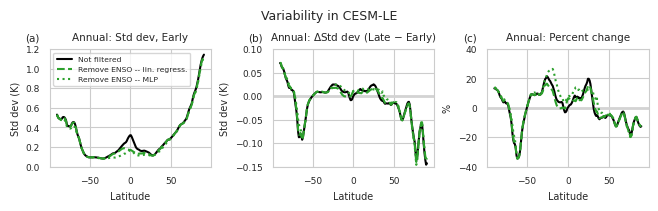

In [5]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib import rcParams


scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})

fig, (ax1,ax2,ax3) = plt.subplots(1, 3, figsize=(6.47, 2),constrained_layout=True)



#ANNUAL
(temp_variance_meanlon_2000to2025).plot(ax=ax1,color='black')
(temp_variance_meanlon_2000to2025_linfilter).plot(ax=ax1,color='tab:green',linestyle='dashed')
(temp_variance_meanlon_2000to2025_mlpfilter).plot(ax=ax1,color='tab:green',linestyle='dotted')
ax1.legend(['Not filtered','Remove ENSO -- lin. regress.','Remove ENSO -- MLP'])
ax1.set_title('Annual: Std dev, Early')
ax1.set_title('(a)',loc='left',x=-0.15)
ax1.set_xlabel('Latitude')
ax1.set_ylabel('Std dev (K)')
ax1.set_ylim([0,1.2])

ax2.axhline(0,color='lightgray',linewidth=2)

(temp_variance_meanlon_2075to2100-temp_variance_meanlon_2000to2025).plot(ax=ax2,color='black')
(temp_variance_meanlon_2075to2100_linfilter-temp_variance_meanlon_2000to2025_linfilter).plot(ax=ax2,color='tab:green',linestyle='dashed')
(temp_variance_meanlon_2075to2100_mlpfilter-temp_variance_meanlon_2000to2025_mlpfilter).plot(ax=ax2,color='tab:green',linestyle='dotted')
ax2.set_title(r'Annual: $\Delta$Std dev (Late − Early)')
ax2.set_title('(b)',loc='left',x=-0.15)
ax2.set_xlabel('Latitude')
ax2.set_ylabel('Std dev (K)')
ax2.set_ylim([-0.15,0.1])

ax3.axhline(0,color='lightgray',linewidth=2)

(100*(temp_variance_meanlon_2075to2100-temp_variance_meanlon_2000to2025)/temp_variance_meanlon_2000to2025).plot(ax=ax3,color='black')
(100*(temp_variance_meanlon_2075to2100_linfilter-temp_variance_meanlon_2000to2025_linfilter)/temp_variance_meanlon_2000to2025_linfilter).plot(ax=ax3,color='tab:green',linestyle='dashed')
(100*(temp_variance_meanlon_2075to2100_mlpfilter-temp_variance_meanlon_2000to2025_mlpfilter)/temp_variance_meanlon_2000to2025_mlpfilter).plot(ax=ax3,color='tab:green',linestyle='dotted')
ax3.set_title('Annual: Percent change')
ax3.set_title('(c)',loc='left',x=-0.15)
ax3.set_xlabel('Latitude')
ax3.set_ylabel('%')
ax3.set_ylim([-40,40])








fig.suptitle('Variability in CESM-LE',fontsize=18*scaling)


import matplotlib
matplotlib.pyplot.savefig('fig1_annualonly_fixedfiltering_updatedtitleandfilter_var_5oct.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)
plt.show()

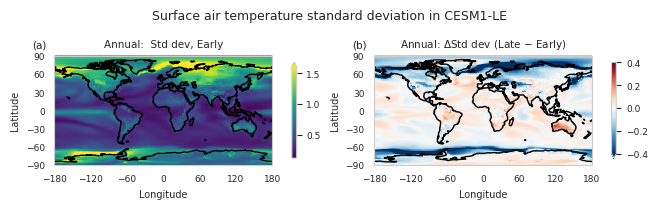

In [6]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib import rcParams


scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})

fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(6.47, 2),constrained_layout=True,subplot_kw={'projection': ccrs.PlateCarree()})


cbar_settings = {"shrink": 0.6, "label": ""}


#Annual
temp_variance_mean_time_nomeanlon=temp_sat[:,:,:,:].coarsen(time=12).mean().var('ensemble_member')
(temp_variance_mean_time_nomeanlon[80:80+26,:,:].mean('time')**0.5).plot(ax=ax1,vmax=1.6,edgecolor='face', cbar_kwargs=cbar_settings)
ax1.set_title('Annual:  Std dev, Early')
ax1.coastlines(resolution='110m', linewidth=1)
ax1.set_title('(a)',loc='left',x=-0.1)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax1.set_xticks([-180,-120,-60,0,60,120,180])
ax1.set_yticks([-90,-60,-30,0,30,60,90])


temp_variance_mean_time_nomeanlon=temp_sat[:,:,:,:].coarsen(time=12).mean().var('ensemble_member')
(temp_variance_mean_time_nomeanlon[-26:,:,:].mean('time')**0.5-temp_variance_mean_time_nomeanlon[80:80+26,:,:].mean('time')**0.5).plot(ax=ax2,vmax=0.4,edgecolor='face', cbar_kwargs=cbar_settings)
ax2.set_title(r'Annual: $\Delta$Std dev (Late − Early)')
ax2.coastlines(resolution='110m', linewidth=1)
ax2.set_title('(b)',loc='left',x=-0.1)
ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')
ax2.set_xticks([-180,-120,-60,0,60,120,180])
ax2.set_yticks([-90,-60,-30,0,30,60,90])



fig.suptitle('Surface air temperature standard deviation in CESM1-LE',fontsize=18*scaling)

import matplotlib
matplotlib.pyplot.savefig('map_standarddev_annualonly_oct5.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)

# Compare zonal mean picture over time

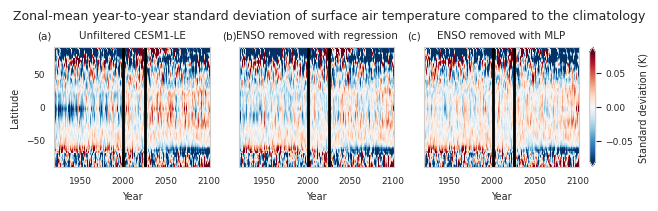

In [7]:
fig, ((ax1, ax2,ax3)) = plt.subplots(
    1, 3,
    figsize=(6.47,2),constrained_layout=True)

scaling=1/2 #use 1 if half width plot once put into latex. use 1/2 if full width once put into latex
rcParams.update({
    'font.size': 10 * scaling,
    'axes.titlesize': 15 * scaling,
    'axes.labelsize': 14 * scaling,
    'xtick.labelsize': 13 * scaling,
    'ytick.labelsize': 13 * scaling,
    'legend.fontsize': 11 * scaling,
})

(temp_variance_mean_time[:,:]**0.5-temp_variance_mean_time[80:80+26,:].mean('time')**0.5).T.plot(vmax=0.08,ax=ax1, add_colorbar=False,edgecolor='face')
(temp_variance_mean_time_linfilter[:,:]**0.5-temp_variance_mean_time_linfilter[80:80+26,:].mean('time')**0.5).T.plot(vmax=0.08,ax=ax2, add_colorbar=False,edgecolor='face')
(temp_variance_mean_time_mlpfilter[:,:]**0.5-temp_variance_mean_time_mlpfilter[:,80:80+26].mean('time')**0.5).plot(vmax=0.08,ax=ax3,edgecolor='face',cbar_kwargs = {'label': 'Standard deviation (K)', 'pad': 0})

ax1.set_title('Unfiltered CESM1-LE')
ax1.set_title('(a)',loc='left',x=-0.11)

ax2.set_title('ENSO removed with regression')
ax2.set_title('(b)',loc='left',x=-0.11)

ax3.set_title('ENSO removed with MLP')
ax3.set_title('(c)',loc='left',x=-0.11)


ax1.set_xlabel('Year')
ax2.set_xlabel('Year')
ax3.set_xlabel('Year')

ax2.tick_params(axis='y', labelleft=False)
ax3.tick_params(axis='y', labelleft=False)


ax1.set_ylabel('Latitude')
ax2.set_ylabel('')
ax3.set_ylabel('')

x_2025 = temp_variance_mean_time.time.where(
    temp_variance_mean_time.time.dt.year == 2025,
    drop=True
)

x_2000 = temp_variance_mean_time.time.where(
    temp_variance_mean_time.time.dt.year == 2000,
    drop=True
)
for ax in (ax1, ax2, ax3):
    ax.axvline(x_2025.values[0], lw=2, color='black')
    ax.axvline(x_2000.values[0], lw=2, color='black')


fig.suptitle('Zonal-mean year-to-year standard deviation of surface air temperature compared to the climatology',fontsize=18*scaling)
import matplotlib
matplotlib.pyplot.savefig('zonalmeanovertime_linregress_mlp_annualonly_fixedfiltering_oct5.pdf', dpi=500,bbox_inches='tight',facecolor='white',transparent=False)